# Monitoring sites — description et anomalies spatiales
**G05 — contribution Merieme.** Analyse autonome de `monitoring_sites`, après le nettoyage conservé dans `monitoring_sites_orchard_surveys.ipynb`.

**Question :** certains sites ont-ils des coordonnées impossibles, répétées ou atypiques par rapport à leur région ?
Une localisation rare n'est pas une erreur. Les lieux du projet sont fictifs : la carte montre uniquement la cohérence interne des coordonnées, sans géocodage réel.

**Alignement groupe :** statistiques descriptives, tableaux croisés, IQR/Z-score/Z modifié et LOF (présents dans `bat_surveys`, `environmental_monthly`, `erp_facilities` et `health/patterns_anomalies`). DBSCAN global séparerait surtout les trois régions ; IF avec quota sur 64 sites imposerait des anomalies. Ils ne sont pas ajoutés ici.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import binom, fisher_exact
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
import sklearn, scipy, sys

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/data_dictionary.csv').exists()), None)
assert ROOT is not None, "Lancer le notebook depuis le dépôt."
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': .2,
                     'font.size': 10, 'figure.dpi': 100})
pd.set_option('display.max_columns', 18)
pd.set_option('display.max_rows', 25)
print('Versions :', sys.version.split()[0], 'pandas', pd.__version__,
      'numpy', np.__version__, 'scikit-learn', sklearn.__version__, 'scipy', scipy.__version__)

def lecture(nom, domaine, cle):
    raw = pd.read_csv(ROOT / 'data' / domaine / (nom + '.csv'))
    path = ROOT / 'data' / domaine / 'cleaned' / (nom + '_cleaned.csv')
    clean = pd.read_csv(path)
    display(pd.DataFrame({'source': ['brut', 'nettoyé'],
                          'lignes': [len(raw), len(clean)],
                          'colonnes': [raw.shape[1], clean.shape[1]],
                          'doublons_exacts': [raw.duplicated().sum(), clean.duplicated().sum()],
                          'doublons_cle': [raw.duplicated(cle).sum(), clean.duplicated(cle).sum()]}))
    display(pd.DataFrame({'type': clean.dtypes.astype(str), 'manquants': clean.isna().sum()}))
    assert clean[cle].notna().all() and clean[cle].is_unique, "Clé primaire à vérifier."
    return raw, clean

def statistiques(data, cle, variables, groupes=(), min_n=8, haut_seul=False):
    """Comparaisons rétrospectives au sein de groupes homogènes ; aucune imputation."""
    records = []
    grouped = data.groupby(list(groupes), dropna=False, sort=True) if groupes else [('ensemble', data)]
    for key, group in grouped:
        if groupes:
            keys = key if isinstance(key, tuple) else (key,)
            label = '; '.join(f'{c}={v}' for c, v in zip(groupes, keys))
        else:
            label = 'ensemble'
        for variable in variables:
            x = pd.to_numeric(group[variable], errors='raise').replace([np.inf, -np.inf], np.nan)
            good = x.dropna()
            n = len(good)
            q1, q3 = good.quantile([.25, .75]) if n else (np.nan, np.nan)
            iqr, mean, sd = q3 - q1, good.mean(), good.std(ddof=1)
            med = good.median()
            mad = (good - med).abs().median()
            specs = [
                ('IQR', q1-1.5*iqr, q3+1.5*iqr, x, iqr, 'hors Q1−1.5×IQR ; Q3+1.5×IQR'),
                ('Z-score', mean-3*sd, mean+3*sd, (x-mean)/sd if sd > 0 else x*0+np.nan, sd, '|z| > 3'),
                ('Z-modifie', med-3.5*mad/.6745, med+3.5*mad/.6745,
                 .6745*(x-med)/mad if mad > 0 else x*0+np.nan, mad, '|z_mod| > 3.5'),
            ]
            for method, lo, hi, scores, spread, rule in specs:
                usable = n >= min_n and pd.notna(spread) and spread > 1e-12
                if haut_seul: lo = -np.inf; rule += ' (queue haute uniquement)'
                for idx in group.index:
                    available = bool(usable and pd.notna(x.loc[idx]))
                    flag = bool(available and (x.loc[idx] < lo or x.loc[idx] > hi))
                    records.append({
                        'observation': str(group.at[idx, cle]), 'groupe': label,
                        'variable': variable, 'methode': method, 'valeur': x.loc[idx],
                        'score': scores.loc[idx] if available else np.nan,
                        'borne_basse': lo if usable else np.nan, 'borne_haute': hi if usable else np.nan,
                        'n_reference': n, 'applicable': available, 'signalee': flag,
                        'regle': rule if usable else f'Non évalué : n < {min_n} ou dispersion nulle',
                        'interpretation': 'Valeur atypique dans ce groupe ; contrôle du contexte nécessaire, pas une erreur établie.'
                    })
    return pd.DataFrame(records)

def resume_tests(tests):
    display(tests.groupby(['variable', 'methode']).agg(
        evaluations=('applicable', 'sum'), signalees=('signalee', 'sum')).reset_index())
    skipped = tests.loc[~tests.applicable, ['groupe','variable','methode','regle']].drop_duplicates()
    if len(skipped):
        print('Cas non évalués (extrait) :'); display(skipped.head(12))

def bh(pvalues):
    """Benjamini–Hochberg : ajustement descriptif des comparaisons multiples."""
    pvalues = np.asarray(pvalues, dtype=float)
    result = np.full(len(pvalues), np.nan)
    good = np.flatnonzero(np.isfinite(pvalues))
    if len(good):
        order = good[np.argsort(pvalues[good])]
        adjusted = pvalues[order] * len(good) / np.arange(1, len(good)+1)
        result[order] = np.minimum.accumulate(adjusted[::-1])[::-1].clip(0,1)
    return result

def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    rate = k/n; den = 1+z*z/n
    center = (rate+z*z/(2*n))/den
    half = z*np.sqrt(rate*(1-rate)/n+z*z/(4*n*n))/den
    # Les bornes exactes k=0/k=n évitent les erreurs d'arrondi à 1e-17.
    low = np.where(k == 0, 0., np.clip(center-half, 0, 1))
    high = np.where(k == n, 1., np.clip(center+half, 0, 1))
    return low, high

def frequences(data, facility, date):
    """Panel entre premier et dernier mois observés, y compris les zéros enregistrés."""
    frames = []
    for name, g in data.groupby(facility):
        periods = g[date].dt.to_period('M')
        grid = pd.period_range(periods.min(), periods.max(), freq='M')
        counts = periods.value_counts().reindex(grid, fill_value=0).sort_index()
        out = pd.DataFrame({'etablissement':name, 'mois':grid.to_timestamp(), 'n':counts.values})
        # Bords exclus : premier/dernier mois d'activité observée potentiellement incomplets.
        out['interieur'] = (np.arange(len(out)) > 0) & (np.arange(len(out)) < len(out)-1)
        out['historique_12'] = out['n'].shift(1).rolling(12, min_periods=12).sum()
        past_complete = out['interieur'].shift(1).rolling(12, min_periods=12).sum().eq(12)
        out['eligible'] = out['interieur'] & past_complete
        out['p_pic'] = np.nan
        ix = out['eligible']
        # Sous un taux constant, conditionnellement au total, le mois testé représente 1/13 de l'exposition.
        total = (out.loc[ix,'historique_12']+out.loc[ix,'n']).astype(int)
        out.loc[ix,'p_pic'] = binom.sf(out.loc[ix,'n']-1, total, 1/13)
        out['observation'] = str(name)+'|'+out['mois'].dt.strftime('%Y-%m')
        frames.append(out)
    out = pd.concat(frames, ignore_index=True)
    out['q_pic'] = bh(out.p_pic)
    out['pic_BH'] = out.q_pic.lt(.05)
    return out

def test_pics(panel):
    result = pd.DataFrame({
        'observation': panel.observation, 'groupe':panel.etablissement,
        'variable':'nombre_mensuel', 'methode':'Binomial_conditionnel_BH',
        'valeur': panel.n, 'score':panel.q_pic,
        'historique_12':panel.historique_12, 'p_brut':panel.p_pic,
        'borne_basse':0., 'borne_haute':.05, 'n_reference':12,
        'applicable':panel.eligible, 'signalee':panel.pic_BH,
        'regle':'q_BH < 0.05 ; comparaison aux 12 mois précédents, bords exclus',
        'interpretation':"Pic exploratoire sous hypothèse de taux constant et couverture continue ; vérifier collecte et saisonnalité."
    })
    return result

def bilan(tests, nom, domaine):
    """Conserve toutes les détections avec leur méthode ; une ligne peut être signalée plusieurs fois."""
    tests = tests.copy()
    tests['echelle_seuil'] = np.where(tests.methode.isin(['Binomial_conditionnel_BH','Fisher_exact_BH','IF','LOF','LOF_k5']), 'score', 'valeur')
    flagged = tests.loc[tests.signalee].copy()
    output = ROOT / 'data' / domaine / 'syntheses'
    output.mkdir(parents=True, exist_ok=True)
    flagged.to_csv(output / (nom+'_anomalies.csv'), index=False)
    # Les bornes restent interprétables avec variable, méthode et effectif de référence.
    cols = ['groupe','variable','methode','borne_basse','borne_haute','n_reference','regle','echelle_seuil']
    tests[cols].drop_duplicates().to_csv(output / (nom+'_seuils.csv'), index=False)
    assert flagged.observation.notna().all()
    print(f'{len(flagged)} détections ; {flagged.observation.nunique()} identifiants distincts (unités d’analyse précisées dans le notebook).')
    display(flagged.head(20))
    return flagged


Versions : 3.9.6 pandas 2.3.3 numpy 2.0.2 scikit-learn 1.6.1 scipy 1.13.1


## 1. Audit des sources et variables
Une ligne = un site. Latitude/longitude servent à calculer des distances terrestres ; les catégories restent qualitatives. L'altitude absente n'est pas imputée. Les dates de fin vides sont compatibles avec des programmes toujours actifs.

In [2]:
raw, df = lecture('monitoring_sites','ecology','site_code')
display(df.head())
for col in ['latitude','longitude','elevation_m']:
    df[col] = pd.to_numeric(df[col], errors='raise')
df['coord_valides'] = df.latitude.between(-90,90) & df.longitude.between(-180,180)
df['coord_dupliquees'] = df.duplicated(['latitude','longitude'], keep=False) & df.coord_valides
starts = pd.to_datetime(df.programme_start_date, errors='raise')
ends = pd.to_datetime(df.programme_end_date, errors='raise')
print('Coordonnées hors domaine/manquantes :', (~df.coord_valides).sum())
print('Sites partageant exactement des coordonnées :', df.coord_dupliquees.sum())
print('Dates de fin avant début :', (ends < starts).sum())
display(df.loc[~df.coord_valides | df.coord_dupliquees])
display(df.loc[df.elevation_m.isna(), ['site_code','elevation_m']])


,source,lignes,colonnes,doublons_exacts,doublons_cle
0,brut,64,14,0,0
1,nettoyé,64,14,0,0


,type,manquants
site_code,object,0
site_name,object,0
site_category,object,0
region,object,0
jurisdiction,object,0
latitude,float64,0
longitude,float64,0
elevation_m,float64,1
habitat_category,object,0
cave_access_category,object,0


,site_code,site_name,site_category,region,jurisdiction,latitude,longitude,elevation_m,habitat_category,cave_access_category,orchard_context,programme_start_date,programme_end_date,site_status
0,KNT-KES,Kestrel Cavern Monitoring Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.68,112.31,248.0,karst_habitat,managed,none recorded,2016-01-01,NaN,active
1,KNT-LUM,Luma Karst Reserve Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.81,112.44,25.0,karst_habitat,managed,none recorded,2016-01-01,NaN,active
2,KNT-SEN,Senna Ridge Cave Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.59,112.50,45.0,karst_habitat,managed,none recorded,2016-01-01,NaN,active
3,AVL-MAR,Marula East Orchard Site,orchard monitoring,Eastern Avelora Agricultural Cluster,Avelora Federation,7.41,101.69,226.0,durian_orchard,not applicable,commercial or research orchard,2016-01-01,NaN,active
4,AVL-VEL,Velin Basin Orchard Site,orchard monitoring,Eastern Avelora Agricultural Cluster,Avelora Federation,7.55,101.84,24.0,durian_orchard,not applicable,commercial or research orchard,2016-01-01,NaN,active


Coordonnées hors domaine/manquantes : 0
Sites partageant exactement des coordonnées : 0
Dates de fin avant début : 0


,site_code,site_name,site_category,region,jurisdiction,latitude,longitude,elevation_m,habitat_category,cave_access_category,orchard_context,programme_start_date,programme_end_date,site_status,coord_valides,coord_dupliquees


,site_code,elevation_m
8,KNT-CYP,NaN


## 2. Répartition des sites
Les effectifs décrivent le plan d'échantillonnage. Une catégorie peu fréquente peut être légitime et ne sera pas assimilée à une anomalie.

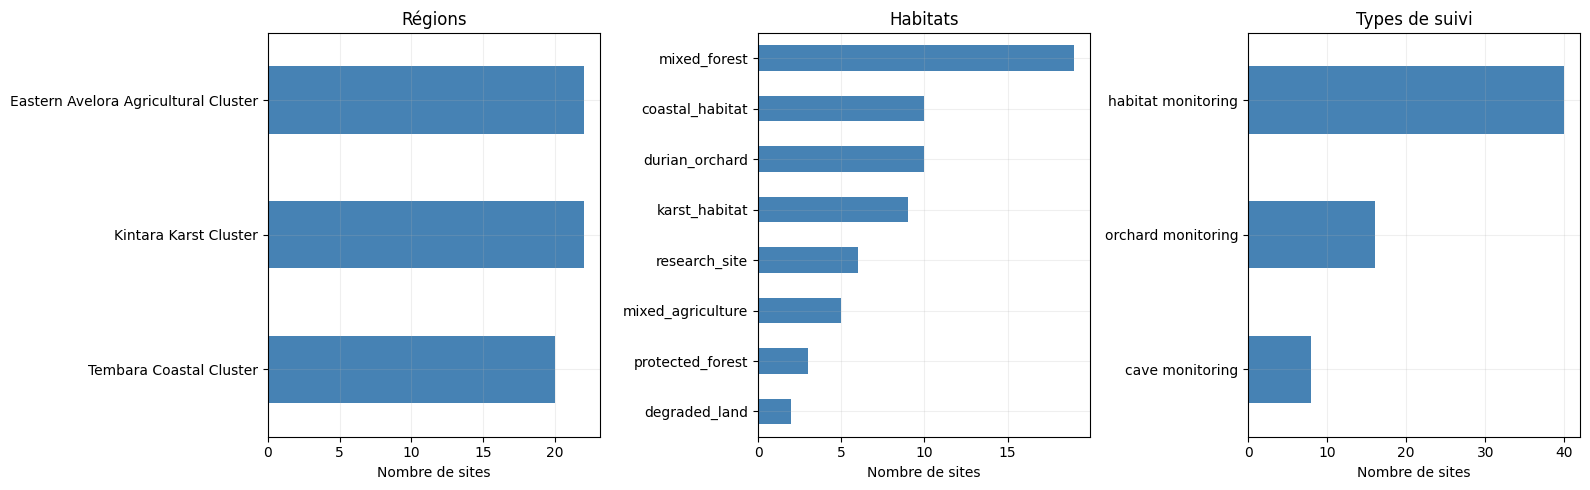

site_category,cave monitoring,habitat monitoring,orchard monitoring
region,,,
Eastern Avelora Agricultural Cluster,0,9,13
Kintara Karst Cluster,7,15,0
Tembara Coastal Cluster,1,16,3


habitat_category,coastal_habitat,degraded_land,durian_orchard,karst_habitat,mixed_agriculture,mixed_forest,protected_forest,research_site
site_category,,,,,,,,
cave monitoring,1,0,0,7,0,0,0,0
habitat monitoring,9,2,0,2,0,19,3,5
orchard monitoring,0,0,10,0,5,0,0,1


**Lecture :** ces répartitions décrivent des sites sélectionnés, pas la fréquence de ces habitats dans le territoire. Les groupes géographiques doivent être analysés séparément.

In [3]:
fig, axes = plt.subplots(1,3,figsize=(16,5))
for ax, column, title in zip(axes, ['region','habitat_category','site_category'],
                             ['Régions','Habitats','Types de suivi']):
    df[column].value_counts().sort_values().plot.barh(ax=ax, color='steelblue')
    ax.set_title(title); ax.set_xlabel('Nombre de sites'); ax.set_ylabel('')
fig.tight_layout(); plt.show()
display(pd.crosstab(df.region, df.site_category))
display(pd.crosstab(df.site_category, df.habitat_category))
display(Markdown("**Lecture :** ces répartitions décrivent des sites sélectionnés, pas la fréquence de ces habitats dans le territoire. Les groupes géographiques doivent être analysés séparément."))


## 3. Carte et distances par région
La carte globale localise les trois groupes ; les panneaux régionaux rendent les écarts locaux visibles. La distance de Haversine est exprimée en kilomètres. La médiane régionale des coordonnées est un centre descriptif, pas une frontière administrative.

Région déclarée différente du centre régional le plus proche : 0


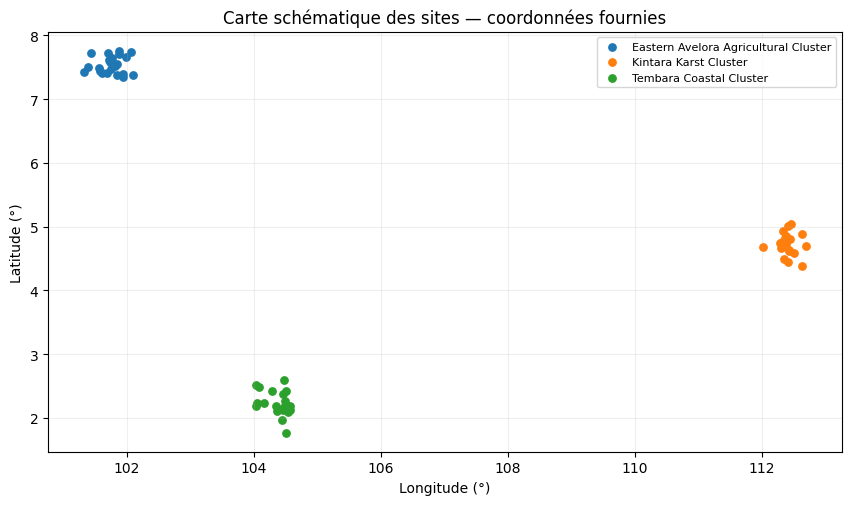

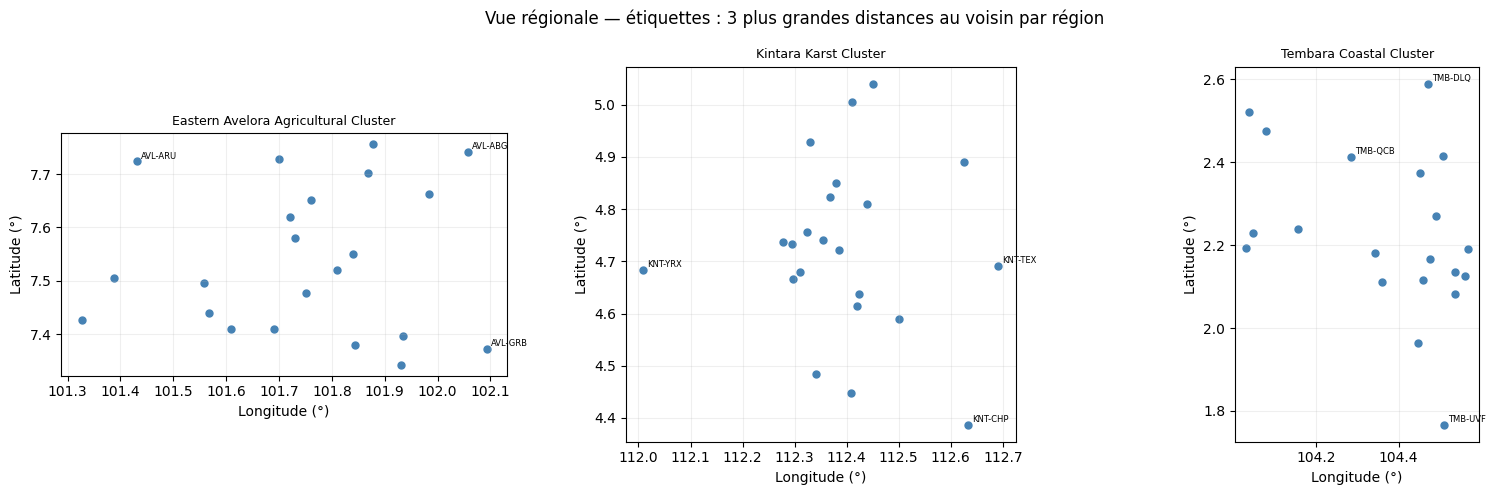

In [4]:
from sklearn.metrics.pairwise import haversine_distances
EARTH_KM = 6371.0088
valid = df.loc[df.coord_valides].copy()
df['distance_centre_km'] = np.nan
df['distance_voisin_km'] = np.nan
df['region_plus_proche'] = pd.NA
centers = valid.groupby('region')[['latitude','longitude']].median()
for region, g in valid.groupby('region'):
    rad = np.radians(g[['latitude','longitude']].to_numpy())
    center = np.radians(centers.loc[[region]].to_numpy())
    dist = haversine_distances(rad)*EARTH_KM
    np.fill_diagonal(dist, np.inf)
    df.loc[g.index, 'distance_centre_km'] = (haversine_distances(rad, center)*EARTH_KM)[:,0]
    df.loc[g.index, 'distance_voisin_km'] = dist.min(axis=1) if len(g)>1 else np.nan
all_centers = haversine_distances(np.radians(valid[['latitude','longitude']]),
                                 np.radians(centers))*EARTH_KM
df.loc[valid.index,'region_plus_proche'] = centers.index.to_numpy()[all_centers.argmin(axis=1)]
print('Région déclarée différente du centre régional le plus proche :',
      (df.loc[valid.index,'region_plus_proche'] != valid.region).sum())
fig, ax = plt.subplots(figsize=(9,5))
for region,g in valid.groupby('region'):
    ax.scatter(g.longitude,g.latitude,label=region,s=28)
ax.set_xlabel('Longitude (°)');ax.set_ylabel('Latitude (°)')
ax.set_title('Carte schématique des sites — coordonnées fournies')
ax.set_aspect(1/np.cos(np.radians(valid.latitude.mean())))
ax.legend(fontsize=8);fig.tight_layout();plt.show()

fig,axes=plt.subplots(1,len(centers),figsize=(16,5))
for ax,(region,g) in zip(axes,valid.groupby('region')):
    ax.scatter(g.longitude,g.latitude,s=25,color='steelblue')
    # Trois sites les plus isolés de chaque région sont étiquetés ; tous restent visibles.
    for _, row in df.loc[g.index].nlargest(3, 'distance_voisin_km').iterrows():ax.annotate(row.site_code,(row.longitude,row.latitude),fontsize=6,xytext=(3,2),textcoords='offset points')
    ax.set_title(region,fontsize=9);ax.set_xlabel('Longitude (°)');ax.set_ylabel('Latitude (°)')
    ax.set_aspect(1/np.cos(np.radians(g.latitude.mean())))
fig.suptitle('Vue régionale — étiquettes : 3 plus grandes distances au voisin par région')
fig.tight_layout();plt.show()


### Règles de lecture communes
IQR : bornes Q1 − 1,5×IQR et Q3 + 1,5×IQR ; Z-score : |z| > 3 ; Z modifié : 0,6745×(x−médiane)/MAD, seuil 3,5.
Ces seuils exploratoires viennent des notebooks du groupe, pas d'une vérité terrain.
Les groupes de moins de 8 observations et les dispersions nulles sont déclarés **non évaluables** : pas de division par zéro, ni de classement automatique de toute valeur non nulle comme anomalie.
Les comparaisons utilisent des groupes explicites ; elles sont rétrospectives et n'estiment pas une causalité.
Les résultats complets signalés et les seuils sont exportés uniquement dans `syntheses/`. Les fichiers bruts et nettoyés ne sont pas modifiés.


In [5]:
tests = statistiques(df,'site_code',['distance_centre_km','distance_voisin_km','elevation_m'],['region'])
resume_tests(tests)
stat_ids = tests.loc[tests.signalee,'observation'].unique()
display(df.loc[df.site_code.isin(stat_ids), ['site_code','region','latitude','longitude',
          'distance_centre_km','distance_voisin_km','elevation_m']])
display(Markdown("**Lecture :** une altitude élevée et une distance inhabituelle sont deux signaux différents. Les seuils sont régionaux pour ne pas considérer un groupe géographique entier comme aberrant."))


,variable,methode,evaluations,signalees
0,distance_centre_km,IQR,64,0
1,distance_centre_km,Z-modifie,64,0
2,distance_centre_km,Z-score,64,0
3,distance_voisin_km,IQR,64,6
4,distance_voisin_km,Z-modifie,64,7
5,distance_voisin_km,Z-score,64,1
6,elevation_m,IQR,63,1
7,elevation_m,Z-modifie,63,0
8,elevation_m,Z-score,63,0


Cas non évalués (extrait) :


,groupe,variable,methode,regle
333,region=Kintara Karst Cluster,elevation_m,IQR,hors Q1−1.5×IQR ; Q3+1.5×IQR
355,region=Kintara Karst Cluster,elevation_m,Z-score,|z| > 3
377,region=Kintara Karst Cluster,elevation_m,Z-modifie,|z_mod| > 3.5


,site_code,region,latitude,longitude,distance_centre_km,distance_voisin_km,elevation_m
9,KNT-YRX,Kintara Karst Cluster,4.6832,112.0095,41.611946,30.409173,192.3
15,KNT-CHP,Kintara Karst Cluster,4.3872,112.6329,46.937349,25.766685,418.8
20,KNT-QWU,Kintara Karst Cluster,4.8896,112.6251,32.378559,22.337005,232.5
24,KNT-TEX,Kintara Karst Cluster,4.6917,112.6905,34.380312,23.168032,82.6
29,AVL-ARU,Eastern Avelora Agricultural Cluster,7.7240,101.4303,42.876300,24.773750,314.3
30,AVL-GRB,Eastern Avelora Agricultural Cluster,7.3725,102.0928,40.294713,17.578717,186.4
53,TMB-UVF,Tembara Coastal Cluster,1.7668,104.5100,47.635386,23.133622,53.4


**Lecture :** une altitude élevée et une distance inhabituelle sont deux signaux différents. Les seuils sont régionaux pour ne pas considérer un groupe géographique entier comme aberrant.

## 4. LOF géographique et sensibilité au voisinage
LOF compare la densité autour d'un site à celle de ses voisins **dans sa région**. Distance de Haversine, coordonnées en radians ; pas de StandardScaler sur des angles.
Seuil de lecture LOF > 1,5 (`contamination='auto'`), sans imposer un pourcentage d'anomalies. On compare k=3, 5 et 8 ; le résultat principal est k=5. Un signal qui disparaît avec k mérite davantage de prudence.

k
3    8
5    5
8    6
Name: sites_signales, dtype: int64

k,3,5,8
site_code,,,
AVL-ARU,1.770,1.474,1.371
AVL-SEY,1.547,1.227,1.388
KNT-CHP,1.733,1.519,1.804
KNT-QWU,1.624,1.497,1.562
KNT-TEX,1.618,1.747,1.713
KNT-XAC,1.449,1.367,1.574
KNT-YRX,4.638,3.729,2.430
TMB-CKU,1.776,1.535,1.098
TMB-UVF,3.137,2.816,1.812


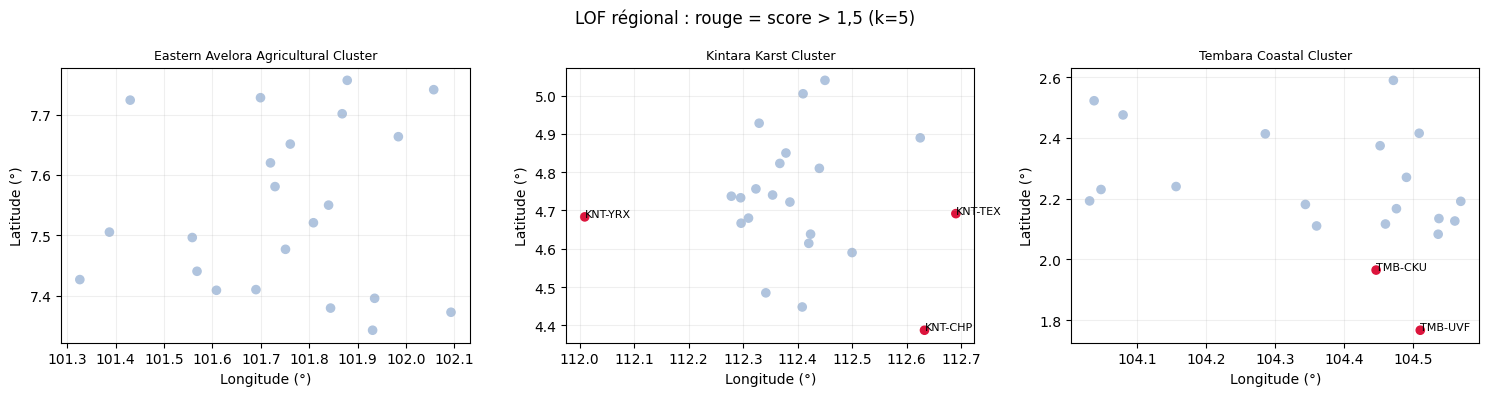

In [6]:
lof_rows=[]
for region,g in df.loc[df.coord_valides].groupby('region'):
    for k in [3,5,8]:
        if len(g)<=k:continue
        model=LocalOutlierFactor(n_neighbors=k,metric='haversine',algorithm='ball_tree',contamination='auto')
        model.fit_predict(np.radians(g[['latitude','longitude']]))
        for idx,score in zip(g.index,-model.negative_outlier_factor_):
            lof_rows.append({'site_code':df.at[idx,'site_code'],'region':region,'k':k,'score':score,'signalee':score>1.5})
lof_scores=pd.DataFrame(lof_rows)
display(lof_scores.groupby('k').signalee.sum().rename('sites_signales'))
lof_main=lof_scores.loc[lof_scores.k.eq(5)].copy()
display(lof_scores.pivot(index='site_code',columns='k',values='score').loc[
    lof_scores.groupby('site_code').signalee.any()].round(3))
lof_tests=pd.DataFrame({
    'observation':lof_main.site_code,'groupe':lof_main.region,'variable':'latitude + longitude (Haversine)',
    'methode':'LOF_k5','valeur':lof_main.score,'score':lof_main.score,
    'borne_basse':-np.inf,'borne_haute':1.5,
    'n_reference':lof_main.region.map(df.region.value_counts()),'applicable':True,
    'signalee':lof_main.signalee,'regle':'LOF > 1.5 ; k=5 ; sensibilité k=3/8',
    'interpretation':'Densité locale inhabituelle ; périphérie ou site isolé possible, localisation à vérifier.'
})
fig,axes=plt.subplots(1,len(centers),figsize=(15,4))
for ax,(region,g) in zip(axes,df.loc[df.coord_valides].groupby('region')):
    marked=g.site_code.isin(lof_main.loc[lof_main.signalee,'site_code'])
    ax.scatter(g.longitude,g.latitude,c=np.where(marked,'crimson','lightsteelblue'),s=35)
    for _,r in g.loc[marked].iterrows():ax.annotate(r.site_code,(r.longitude,r.latitude),fontsize=8)
    ax.set_title(region,fontsize=9);ax.set_xlabel('Longitude (°)');ax.set_ylabel('Latitude (°)')
fig.suptitle('LOF régional : rouge = score > 1,5 (k=5)');fig.tight_layout();plt.show()


## 5. Bilan et observations à vérifier
Les tableaux exportés distinguent chaque variable, méthode, seuil et site. Les signaux statistiques sont conservés sans corriger les coordonnées.

In [7]:
rule_rows=[]
for column,label,flag in [
    ('coord_valides','coordonnées physiques',~df.coord_valides),
    ('coord_dupliquees','coordonnées identiques',df.coord_dupliquees),
    ('region_plus_proche','centre régional différent',df.coord_valides & df.region_plus_proche.ne(df.region)),
]:
    for idx in df.index[flag]:
        rule_rows.append({'observation':df.at[idx,'site_code'],'groupe':df.at[idx,'region'],
            'variable':column,'methode':'Contrôle_coherence','valeur':str(df.at[idx,column]),
            'score':np.nan,'borne_basse':np.nan,'borne_haute':np.nan,'n_reference':len(df),
            'applicable':True,'signalee':True,'regle':label,
            'interpretation':'Contrôle manuel du référentiel ; colocalisation possible si coordonnées partagées.'})
all_tests=pd.concat([tests,lof_tests,pd.DataFrame(rule_rows)],ignore_index=True)
all_tests.loc[all_tests.variable.eq('distance_voisin_km'),'interpretation']='Site éloigné de son voisin régional ; périphérie ou échantillonnage dispersé possible.'
all_tests.loc[all_tests.variable.eq('elevation_m'),'interpretation']='Altitude rare dans la région mais physiquement plausible ; vérifier le relief avant toute correction.'
register=bilan(all_tests,'monitoring_sites','ecology')
summary={
    'sites':len(df),'invalid_coordinates':int((~df.coord_valides).sum()),
    'duplicate_coordinates':int(df.coord_dupliquees.sum()),
    'stats_sites':len(stat_ids),'lof_sites':int(lof_main.signalee.sum()),
    'lof_ids':lof_main.loc[lof_main.signalee,'site_code'].tolist(),
}
display(Markdown(f"**Bilan calculé :** {len(df)} sites ; {summary['invalid_coordinates']} coordonnées impossibles/manquantes ; "
                f"{summary['duplicate_coordinates']} sites colocalisés exactement ; "
                f"{summary['stats_sites']} sites signalés par au moins un test statistique régional, "
                f"{summary['lof_sites']} par LOF k=5. "
                "L'altitude absente reste inconnue. Les coordonnées ne permettent pas de confirmer une localisation réelle dans cet univers fictif."))
assert len(df)==len(raw)


20 détections ; 8 identifiants distincts (unités d’analyse précisées dans le notebook).


,observation,groupe,variable,methode,valeur,score,borne_basse,borne_haute,n_reference,applicable,signalee,regle,interpretation,echelle_seuil
71,AVL-ARU,region=Eastern Avelora Agricultural Cluster,distance_voisin_km,IQR,24.773750,24.773750,-2.380776,19.041579,22,True,True,hors Q1−1.5×IQR ; Q3+1.5×IQR,Site éloigné de son voisin régional ; périphér...,valeur
93,AVL-ARU,region=Eastern Avelora Agricultural Cluster,distance_voisin_km,Z-score,24.773750,3.275823,-5.944431,23.423684,22,True,True,|z| > 3,Site éloigné de son voisin régional ; périphér...,valeur
115,AVL-ARU,region=Eastern Avelora Agricultural Cluster,distance_voisin_km,Z-modifie,24.773750,7.056789,-2.881320,15.456216,22,True,True,|z_mod| > 3.5,Site éloigné de son voisin régional ; périphér...,valeur
116,AVL-GRB,region=Eastern Avelora Agricultural Cluster,distance_voisin_km,Z-modifie,17.578717,4.310224,-2.881320,15.456216,22,True,True,|z_mod| > 3.5,Site éloigné de son voisin régional ; périphér...,valeur
268,KNT-YRX,region=Kintara Karst Cluster,distance_voisin_km,IQR,30.409173,30.409173,-6.430277,18.283845,22,True,True,hors Q1−1.5×IQR ; Q3+1.5×IQR,Site éloigné de son voisin régional ; périphér...,valeur
274,KNT-CHP,region=Kintara Karst Cluster,distance_voisin_km,IQR,25.766685,25.766685,-6.430277,18.283845,22,True,True,hors Q1−1.5×IQR ; Q3+1.5×IQR,Site éloigné de son voisin régional ; périphér...,valeur
279,KNT-QWU,region=Kintara Karst Cluster,distance_voisin_km,IQR,22.337005,22.337005,-6.430277,18.283845,22,True,True,hors Q1−1.5×IQR ; Q3+1.5×IQR,Site éloigné de son voisin régional ; périphér...,valeur
283,KNT-TEX,region=Kintara Karst Cluster,distance_voisin_km,IQR,23.168032,23.168032,-6.430277,18.283845,22,True,True,hors Q1−1.5×IQR ; Q3+1.5×IQR,Site éloigné de son voisin régional ; périphér...,valeur
312,KNT-YRX,region=Kintara Karst Cluster,distance_voisin_km,Z-modifie,30.409173,5.775384,-10.401618,20.397705,22,True,True,|z_mod| > 3.5,Site éloigné de son voisin régional ; périphér...,valeur
318,KNT-CHP,region=Kintara Karst Cluster,distance_voisin_km,Z-modifie,25.766685,4.720249,-10.401618,20.397705,22,True,True,|z_mod| > 3.5,Site éloigné de son voisin régional ; périphér...,valeur


**Bilan calculé :** 64 sites ; 0 coordonnées impossibles/manquantes ; 0 sites colocalisés exactement ; 7 sites signalés par au moins un test statistique régional, 5 par LOF k=5. L'altitude absente reste inconnue. Les coordonnées ne permettent pas de confirmer une localisation réelle dans cet univers fictif.

## 6. Vérification complémentaire M2 — cohérence avec les sites de vergers

Les sites déclarés « verger » dans le référentiel doivent être rapprochés des `site_code` réellement présents dans les relevés de vergers. Cette **vérification de couverture** ne prétend pas valider les coordonnées ni prouver l'exhaustivité de l'échantillonnage. Elle permet d'éviter de conclure qu'un site est absent simplement parce que sa catégorie a été saisie différemment. On conserve les deux jeux de données sans les modifier.


In [8]:
vergers_path = ROOT / 'data/ecology/cleaned/orchard_surveys_cleaned.csv'
vergers_refs = pd.read_csv(vergers_path, usecols=['site_code']).drop_duplicates()
assert vergers_refs.site_code.is_unique
coverage_sites = df[['site_code','region','orchard_context','site_category']].merge(
    vergers_refs.assign(releve_verger=True), on='site_code', how='left', validate='one_to_one')
coverage_sites['releve_verger'] = coverage_sites.releve_verger.fillna(False).astype(bool)
coverage_sites['contexte_verger'] = coverage_sites.orchard_context.eq('commercial or research orchard')
print('Sites avec relevés verger :', int(coverage_sites.releve_verger.sum()))
print('Sites déclarés en contexte verger :', int(coverage_sites.contexte_verger.sum()))
print('Sites de relevés absents du référentiel :', len(set(vergers_refs.site_code)-set(df.site_code)))
display(pd.crosstab(coverage_sites.contexte_verger,coverage_sites.releve_verger,
                    rownames=['contexte verger'],colnames=['relevé disponible']))
display(coverage_sites.loc[coverage_sites.contexte_verger.ne(coverage_sites.releve_verger)])
assert not (set(vergers_refs.site_code)-set(df.site_code)), 'Références de verger inconnues'
print('Interprétation : couverture des identifiants contrôlée ; ce contrôle ne mesure ni la fiabilité des coordonnées ni la représentativité.')


Sites avec relevés verger : 16
Sites déclarés en contexte verger : 16
Sites de relevés absents du référentiel : 0
relevé disponible  False  True 
contexte verger                
False                 48      0
True                   0     16
Empty DataFrame
Columns: [site_code, region, orchard_context, site_category, releve_verger, contexte_verger]
Index: []
Interprétation : couverture des identifiants contrôlée ; ce contrôle ne mesure ni la fiabilité des coordonnées ni la représentativité.


### Limites et suite
Les régions ne sont décrites par aucun polygone : le centre le plus proche est une heuristique, pas une validation administrative.
Les méthodes détectent des valeurs rares dans 20–22 sites par région ; leurs seuils sont sensibles au faible effectif.
Relire les sites signalés avec le groupe avant toute correction. Aucun lien causal avec les événements écologiques n'est déduit.
**Assistance IA :** préparation du code et de la rédaction ; résultats à relire par le groupe, conformément au README.